In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
from scipy.stats import binom
from scipy.stats import poisson

Load the dataset

In [2]:
#Trips, Nights and Average Length of Stay of Foreign Resident Overnight Visitors
#dataset downloaded from 
# ITM05 https://data.cso.ie/#

tourism=pd.read_csv('Length of Stay of Foreign Resident.csv')

head to see the first 5 raws

In [3]:
tourism.head()

,Statistic Label,Month,Main Accommodation Type,UNIT,VALUE
0,Number of Overnight Trips by Foreign Visitors,2023 January,Hotel/conference centre,Thousand,121.0
1,Number of Overnight Trips by Foreign Visitors,2023 January,Guest house/bed & breakfast,Thousand,8.5
2,Number of Overnight Trips by Foreign Visitors,2023 January,Friends/relatives/own property,Thousand,243.4
3,Number of Overnight Trips by Foreign Visitors,2023 January,Self catering/rented house,Thousand,13.8
4,Number of Overnight Trips by Foreign Visitors,2023 January,Other private tourism accommodation n.e.c.,Thousand,13.4


In [4]:
#to see how many columns and rows it has
tourism.shape

(1320, 5)

In [5]:
#to see if we have nulls and how many columns
tourism.info()

<class 'pandas.DataFrame'>
RangeIndex: 1320 entries, 0 to 1319
Data columns (total 5 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Statistic Label          1320 non-null   str    
 1   Month                    1320 non-null   str    
 2   Main Accommodation Type  1320 non-null   str    
 3   UNIT                     1320 non-null   str    
 4   VALUE                    1320 non-null   float64
dtypes: float64(1), str(4)
memory usage: 166.4 KB


In [6]:
# stadistic properties mean, std, min
tourism.describe()

,VALUE
count,1320.000000
mean,328.579621
std,854.248511
min,1.000000
25%,8.175000
50%,34.000000
75%,204.700000
max,7337.700000


In [7]:
# I can see what types of data I have, mostly str
tourism.dtypes

Statistic Label                str
Month                          str
Main Accommodation Type        str
UNIT                           str
VALUE                      float64
dtype: object

In [8]:
# to see if there are columns missing values
tourism.isnull().sum()

Statistic Label            0
Month                      0
Main Accommodation Type    0
UNIT                       0
VALUE                      0
dtype: int64

**Exploratory Data Analysis (EDA)**

Before applying any statistical models, an Exploratory Data Analysis was conducted to understand the dataset's structure and quality.

**Data Quality Insights:**

1. Structure & Types: The dataset has 1,320 rows and 5 columns. We have 4 string columns (categorical) and 1 numeric column (VALUE), which is already a float.
2. Missing Values: isnull().sum() confirmed there are no missing values, so no imputation is required for the raw dataset.
3. Data Structure (Wide vs Long): The value_counts() method revealed that VALUE mixes 5 different metrics (trips, nights, percentages, etc.). Mixing these would yield invalid statistics, which justified filtering by Statistic Label for all subsequent analyses.
4. Distribution & Outliers: Using boxplots and the IQR method, we identified 14 outliers in the Number of Overnight Trips. The histogram of Average Length of Stay showed a strong right-skew, indicating non-normality.
* Conclusion: The EDA revealed that the raw data requires careful filtering (by metric) before analysis. For Machine Learning, the dataset will need to be pivoted (wide format) and the categorical variables (Accommodation Type, Month) will need encoding.

Measure of central tendency

In [9]:
# To show the first 5 raws and all columns
tourism.head()


,Statistic Label,Month,Main Accommodation Type,UNIT,VALUE
0,Number of Overnight Trips by Foreign Visitors,2023 January,Hotel/conference centre,Thousand,121.0
1,Number of Overnight Trips by Foreign Visitors,2023 January,Guest house/bed & breakfast,Thousand,8.5
2,Number of Overnight Trips by Foreign Visitors,2023 January,Friends/relatives/own property,Thousand,243.4
3,Number of Overnight Trips by Foreign Visitors,2023 January,Self catering/rented house,Thousand,13.8
4,Number of Overnight Trips by Foreign Visitors,2023 January,Other private tourism accommodation n.e.c.,Thousand,13.4


In [10]:
#Here I noticed that my column statistic label has 5 different metrics with 264 values each
# so i have percentages included so it will not be accurate if I get statistics mixed
print(tourism["Statistic Label"].value_counts())

Statistic Label
Number of Overnight Trips by Foreign Visitors        264
Percentage of Overnight Trips by Foreign Visitors    264
Number of Nights by Foreign Visitors                 264
Percentage of Nights by Foreign Visitors             264
Average Length of Stay of Foreign Visitors           264
Name: count, dtype: int64


In [11]:
#mean
# In my dataset my column value has five metrics, so if apply all
# mixed Ill be getting a wrong mean, so I decided to apply only to one 
# for this case will be trips = Number of Overnight Trips by Foreign Visitors

# Mean of the value if I apply only to the column value which is wrong
mean=tourism["VALUE"].mean()
print (f'The average Value is: {mean}')

The average Value is: 328.5796212121212


Source: pandas Documentation. "pandas.Series.mean". https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.Series.mean.html

How I found it: I searched the official pandas API reference for the mean() method to confirm its default behaviour (arithmetic mean, skipping NaN values).

Quality evaluation: Official pandas documentation, maintained by the pandas development team. It is the primary and authoritative source for pandas methods.

Verification: I ran the code and confirmed that the output is the arithmetic mean of the filtered VALUE column, matching the documented behaviour.

In [12]:
# If I apply only to Trips Ill be separating only to that specific metric inside my column
# statistic label
trips = tourism[tourism["Statistic Label"] == "Number of Overnight Trips by Foreign Visitors"]
print(f"The average Value of Number of Overnight Trips by Foreign Visitors:   {trips['VALUE'].mean():.2f}")

The average Value of Number of Overnight Trips by Foreign Visitors:   181.51


In [13]:
#median only for trips
trips = tourism[tourism["Statistic Label"] == "Number of Overnight Trips by Foreign Visitors"]
print(f"The median Value of Number of Overnight Trips by Foreign Visitors:   {trips['VALUE'].median():.2f}")

The median Value of Number of Overnight Trips by Foreign Visitors:   92.45


In [14]:
# mode, same as for the rest
trips = tourism[tourism["Statistic Label"] == "Number of Overnight Trips by Foreign Visitors"]
mode = trips["VALUE"].mode()
print(mode)
#The mode of Number of Overnight Trips was not informative: 
#out of 264 observations, 247 were unique values, producing 
#17 tied values as the mode. As this is a continuous variable, 
#the mode is not a representative measure; mean and median are reported instead as the 
#main measures of central tendency

0      11.8
1      14.4
2      15.5
3      16.5
4      17.4
5      21.7
6      25.3
7      26.3
8      26.7
9      26.9
10     31.2
11     33.5
12     36.3
13     37.9
14     41.1
15     45.6
16    204.7
Name: VALUE, dtype: float64


In [15]:
# I found this code to get statistics information separated by groups**Source:** pandas Documentation. "pandas.core.groupby.DataFrameGroupBy.describe".

tourism.groupby('Statistic Label')['VALUE'].describe()



,count,mean,std,min,25%,50%,75%,max
Statistic Label,,,,,,,,
Average Length of Stay of Foreign Visitors,264.0,9.762500,6.451704,3.3,6.175,8.00,11.350,56.0
Number of Nights by Foreign Visitors,264.0,1384.963258,1483.625165,28.8,352.250,811.20,1746.475,7337.7
Number of Overnight Trips by Foreign Visitors,264.0,181.509470,193.402125,6.5,29.725,92.45,265.475,788.7
Percentage of Nights by Foreign Visitors,264.0,33.330682,33.212999,1.0,8.100,19.20,43.925,100.0
Percentage of Overnight Trips by Foreign Visitors,264.0,33.332197,34.211792,1.7,5.475,20.55,46.125,100.0


Source: pandas Documentation. "pandas.core.groupby.DataFrameGroupBy.describe". https://pandas.pydata.org/pandas-docs/version/2.2/reference/api/pandas.core.groupby.DataFrameGroupBy.describe.html

How I found it: I searched the official pandas API reference for the groupby().describe() method to confirm that it computes descriptive statistics per group independently.

Quality evaluation: Official pandas documentation, maintained by the pandas development team. It is the primary and authoritative source for pandas methods.

Verification: I ran the code and confirmed that the output contains one set of descriptive statistics per Statistic Label, matching the documented behaviour of grouping before describing.

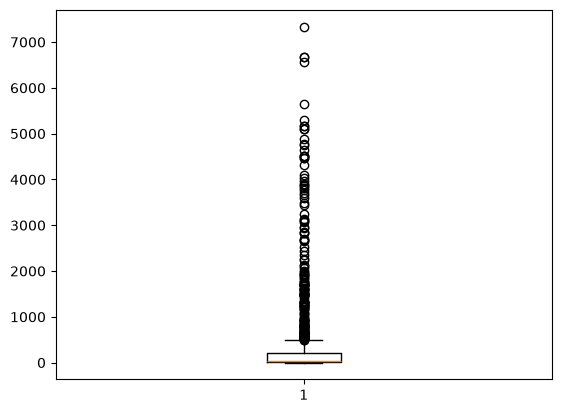

In [16]:
# to check wether the data has outliers or not
#boxplot
#the problem here is that i have many types of statistic labels such as percentaje o lenght of stay
plt.boxplot(tourism["VALUE"])
plt.show()
# this graphic is not accurate because my units are differents

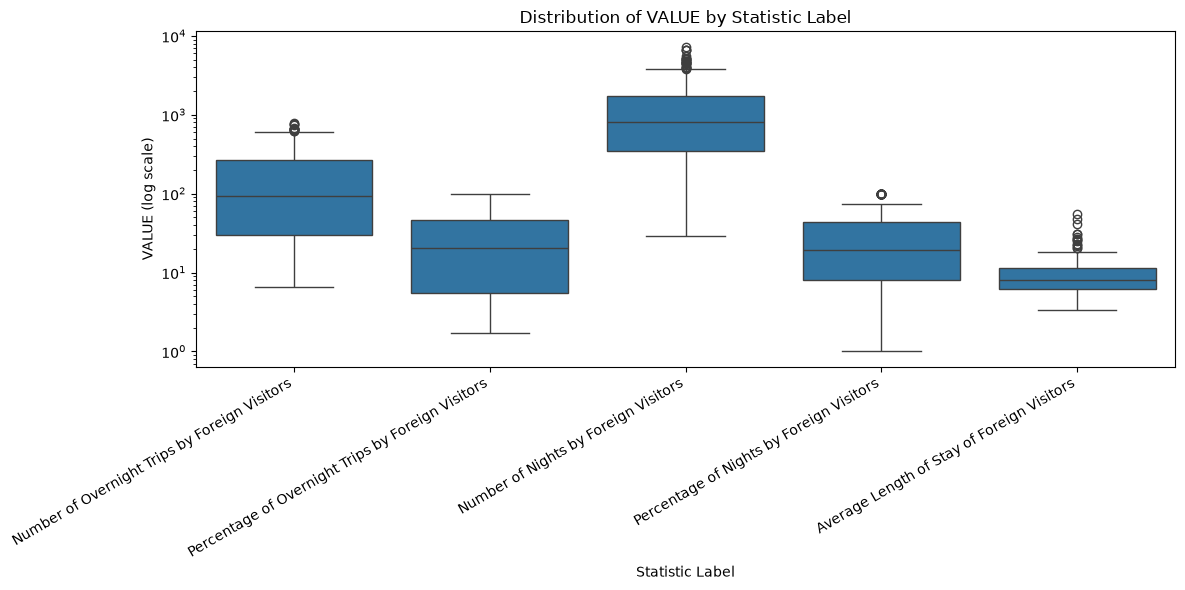

In [17]:
# I am using seaborn as it separates statistic labels by metrics, which i have 5 diferents
plt.figure(figsize=(12, 6))
sns.boxplot(data=tourism, x='Statistic Label', y='VALUE')
plt.yscale('log') #this is to change the dimension to have similar for every metric
plt.xticks(rotation=30, ha='right')
plt.title('Distribution of VALUE by Statistic Label')
plt.ylabel('VALUE (log scale)')
plt.tight_layout()
plt.show()

In [18]:
#measure of dispersion
#to do for all of the five metrics at the same time I am using the next code
summary = tourism.groupby("Statistic Label")["VALUE"].agg(
    Mean="mean",
    Median="median",
    Std="std",
    Min="min",
    Max="max",
    Count="count",
    #Range = max-min
)
summary["Range"] = summary["Max"] - summary["Min"]
print(summary)

                                                          Mean  Median  \
Statistic Label                                                          
Average Length of Stay of Foreign Visitors            9.762500    8.00   
Number of Nights by Foreign Visitors               1384.963258  811.20   
Number of Overnight Trips by Foreign Visitors       181.509470   92.45   
Percentage of Nights by Foreign Visitors             33.330682   19.20   
Percentage of Overnight Trips by Foreign Visitors    33.332197   20.55   

                                                           Std   Min     Max  \
Statistic Label                                                                
Average Length of Stay of Foreign Visitors            6.451704   3.3    56.0   
Number of Nights by Foreign Visitors               1483.625165  28.8  7337.7   
Number of Overnight Trips by Foreign Visitors       193.402125   6.5   788.7   
Percentage of Nights by Foreign Visitors             33.212999   1.0   100.0   
P

The table above shows the central tendency and dispersion measures for all five metrics. By grouping by Statistic Label, we avoid mixing incompatible units (thousands, percentages, and nights per trip).

A key insight is the difference between the Mean and Median for Number of Overnight Trips (Mean: 181.5 vs Median: 92.4). This confirms the positive skewness observed in the histogram, where a few high-demand summer months pull the mean upwards. The Range also highlights that Number of Nights has the highest absolute dispersion (range of 7,308.9), which is expected given the scale of the data.

In [19]:
#min of trips
trips = tourism[tourism["Statistic Label"] == "Number of Overnight Trips by Foreign Visitors"]

print(f"The minimum value of Number of Overnight Trips by Foreign Visitors is: {trips['VALUE'].min():.2f}")

The minimum value of Number of Overnight Trips by Foreign Visitors is: 6.50


In [20]:
trips = tourism[tourism["Statistic Label"] == "Number of Overnight Trips by Foreign Visitors"]

print(f"The maximun value of Number of Overnight Trips by Foreign Visitors is: {trips['VALUE'].max():.2f}")

The maximun value of Number of Overnight Trips by Foreign Visitors is: 788.70


In [21]:
trips = tourism[tourism["Statistic Label"] == "Number of Overnight Trips by Foreign Visitors"]

max_val = trips["VALUE"].max()
min_val = trips["VALUE"].min()
value_range = max_val - min_val

print(f"Max:   {max_val:.2f}")
print(f"Min:   {min_val:.2f}")
print(f"Range: {value_range:.2f}")

Max:   788.70
Min:   6.50
Range: 782.20


In [22]:
#variance
trips = tourism[tourism["Statistic Label"] == "Number of Overnight Trips by Foreign Visitors"]

variance = trips["VALUE"].var()
print(f"Variance: {variance:.2f}")

Variance: 37404.38


In [23]:
# Standard deviation
trips = tourism[tourism["Statistic Label"] == "Number of Overnight Trips by Foreign Visitors"]
std= trips["VALUE"].std()
std

np.float64(193.40212512079233)

In [24]:
# percentile
"""
Q1 ---> quartile 1 --> 25th percentile
Q3 --> quartile 2 --> 75th percentile
IQR = Q3 - Q1
"""
# again here I am using only one metric
trips = tourism[tourism["Statistic Label"] == "Number of Overnight Trips by Foreign Visitors"]

Q1 = trips["VALUE"].quantile(0.25)
Q2 = trips["VALUE"].quantile(0.50)
Q3 = trips["VALUE"].quantile(0.75)
IQR = Q3 - Q1
IQR, Q1, Q2, Q3


(np.float64(235.75000000000003),
 np.float64(29.725),
 np.float64(92.45),
 np.float64(265.475))

In [25]:
#outliers using percentiles
trips = tourism[tourism["Statistic Label"] == "Number of Overnight Trips by Foreign Visitors"]

Q1 = trips["VALUE"].quantile(0.25)

Q3 = trips["VALUE"].quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1 -1.5*IQR
upper_bound = Q3+ 1.5*IQR

outliers = trips[(trips["VALUE"] < lower_bound) | (trips["VALUE"] > upper_bound )]
print ('Lower bound: ', lower_bound)
print ('Upper bound: ', upper_bound)
print (' Number of outliers ', len(outliers))
print (' Number of outliers ', outliers)
outliers

Lower bound:  -323.90000000000003
Upper bound:  619.1000000000001
 Number of outliers  14
 Number of outliers                                     Statistic Label        Month  \
35   Number of Overnight Trips by Foreign Visitors    2023 June   
41   Number of Overnight Trips by Foreign Visitors    2023 July   
47   Number of Overnight Trips by Foreign Visitors  2023 August   
101  Number of Overnight Trips by Foreign Visitors     2024 May   
107  Number of Overnight Trips by Foreign Visitors    2024 June   
113  Number of Overnight Trips by Foreign Visitors    2024 July   
119  Number of Overnight Trips by Foreign Visitors  2024 August   
179  Number of Overnight Trips by Foreign Visitors    2025 June   
185  Number of Overnight Trips by Foreign Visitors    2025 July   
191  Number of Overnight Trips by Foreign Visitors  2025 August   
245  Number of Overnight Trips by Foreign Visitors     2026 May   
251  Number of Overnight Trips by Foreign Visitors    2026 June   
257  Number of Ove

,Statistic Label,Month,Main Accommodation Type,UNIT,VALUE
35,Number of Overnight Trips by Foreign Visitors,2023 June,All types of accommodation,Thousand,619.9
41,Number of Overnight Trips by Foreign Visitors,2023 July,All types of accommodation,Thousand,650.2
47,Number of Overnight Trips by Foreign Visitors,2023 August,All types of accommodation,Thousand,737.6
101,Number of Overnight Trips by Foreign Visitors,2024 May,All types of accommodation,Thousand,622.3
107,Number of Overnight Trips by Foreign Visitors,2024 June,All types of accommodation,Thousand,669.5
113,Number of Overnight Trips by Foreign Visitors,2024 July,All types of accommodation,Thousand,655.4
119,Number of Overnight Trips by Foreign Visitors,2024 August,All types of accommodation,Thousand,763.6
179,Number of Overnight Trips by Foreign Visitors,2025 June,All types of accommodation,Thousand,654.5
185,Number of Overnight Trips by Foreign Visitors,2025 July,All types of accommodation,Thousand,646.4
191,Number of Overnight Trips by Foreign Visitors,2025 August,All types of accommodation,Thousand,772.8


Normal Distribution

In [26]:
# first i am filtering the metric average long of stay of foreign visitors because it is the most
# most continuous variable in the dataset

In [27]:
# los = long of stay
los = tourism[tourism["Statistic Label"] == "Average Length of Stay of Foreign Visitors"]["VALUE"]

print(f"Number of null values: {los.isnull().sum()}")

Number of null values: 0


# To show if the column average length of stay is normally distributed I visualize

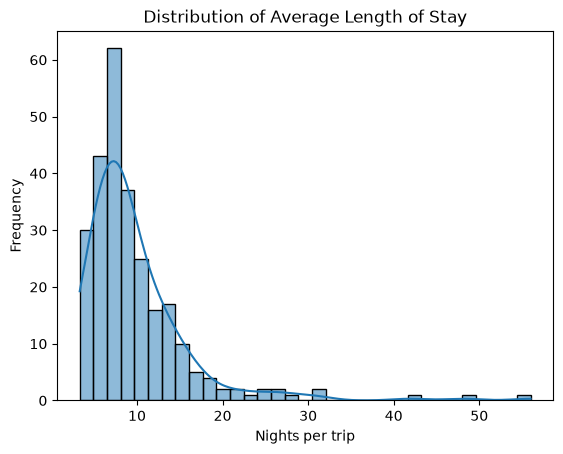

In [28]:
sns.histplot(los, kde=True)
plt.title("Distribution of Average Length of Stay")
plt.xlabel("Nights per trip")
plt.ylabel("Frequency")
plt.show()


the data is not normally distributed. In a normal distribution, the curve would be symmetric around the mean, with equal tails on both sides.

*Empirical rule for normal distribution*

In [29]:
mean = los.mean()
std = los.std()

within1 = ((los >= mean - std) & (los <= mean + std)).mean() * 100
within2 = ((los >= mean - 2*std) & (los <= mean + 2*std)).mean() * 100
within3 = ((los >= mean - 3*std) & (los <= mean + 3*std)).mean() * 100

print(within1,within2,within3)


90.53030303030303 95.83333333333334 98.10606060606061


check normal distribution using z - score

In [30]:
from scipy import stats
z_scores=stats.zscore(los)
z_scores.min(),z_scores.max()

(np.float64(-1.003575902498554), np.float64(7.180323526773987))

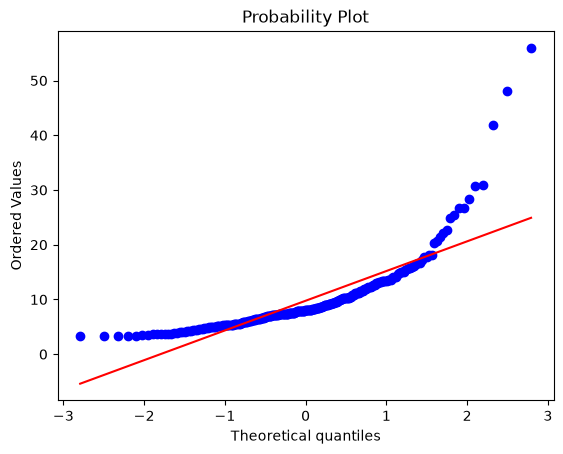

In [31]:
##QQ plot, its another way to know if my column is normally distributed
stats.probplot(los,dist='norm',plot=plt)
plt.show()

In [32]:
#again this graphic shows that is not normal distribution, because the orange line is not together with the blue one and there
# are some points on the end

**Discrete distribution**

Months above threshold per year:
Year
2023    3
2024    4
2025    3
2026    4
Name: success, dtype: int64

Total months per year:
Year
2023    12
2024    12
2025    12
2026     8
Name: success, dtype: int64

Estimated probability (p): 0.2778


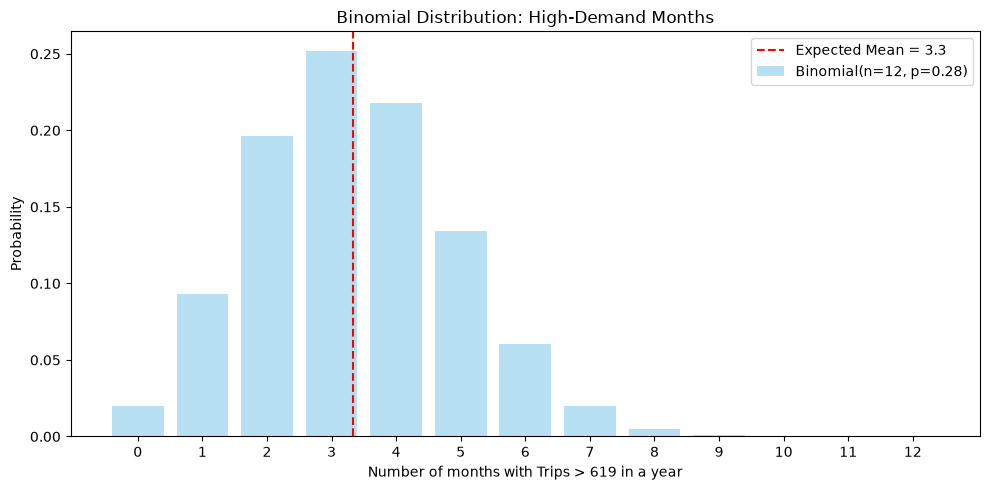

In [33]:
#Binomial Distribution

# 1. Filter to one row per month (All types of accommodation)
monthly = trips[trips["Main Accommodation Type"] == "All types of accommodation"].copy()
monthly["Year"] = monthly["Month"].str[:4]

# 2. Define success (trips > 619)
threshold = 619
monthly["success"] = (monthly["VALUE"] > threshold).astype(int)

# 3. Count successes per year
yearly_success = monthly.groupby("Year")["success"].sum()
yearly_total = monthly.groupby("Year")["success"].count()

print("Months above threshold per year:")
print(yearly_success)
print("\nTotal months per year:")
print(yearly_total)

# 4. Exclude 2026 (only has 8 months)
monthly_full = monthly[monthly["Year"] != "2026"]

# 5. Calculate p (estimated probability of success)
p_hat = monthly_full["success"].mean()
print(f"\nEstimated probability (p): {p_hat:.4f}")

# 6. Plot Binomial(12, p)
n = 12
k = np.arange(0, n + 1)

plt.figure(figsize=(10, 5))
plt.bar(k, binom.pmf(k, n, p_hat), alpha=0.6, color='skyblue', label=f'Binomial(n={n}, p={p_hat:.2f})')
plt.axvline(n * p_hat, color='red', linestyle='--', label=f'Expected Mean = {n * p_hat:.1f}')

plt.xlabel("Number of months with Trips > 619 in a year")
plt.ylabel("Probability")
plt.title("Binomial Distribution: High-Demand Months")
plt.xticks(k)
plt.legend()
plt.tight_layout()
plt.show()